In [12]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [13]:
def f(x):
    return 3*x**2 - 4*x +5


In [14]:
f(3.0)

20.0

In [15]:
f(5.0)

60.0

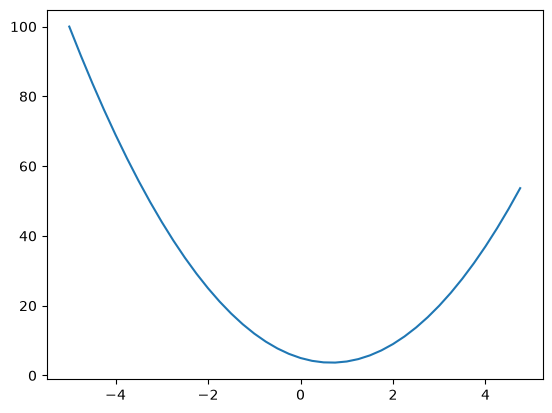

In [16]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

In [17]:
#derivative of the f(X)
#f(x+h)-(h)/h  h tends to zero
h=0.0000001
x=-3.0
slope=(f(x+h)-f(x))/h
slope

-21.999999688659955

In [18]:
#derivative function with mutliple inputs
# evaluting a derivative of d wrt to all the inputs.
a =2.0
b =-3.0
c = 10

d = a*b+c
d

4.0

In [19]:
#derivative of d wrt to a
# d(d)/d(a)
a =2.0
b =-3.0
c = 10
h=0.0001
d1 = a*b +c
a +=h
d2 = a*b+c
print('d1',d1)
print('d2',d2)
print('slope', (d2-d1)/h)

d1 4.0
d2 3.999699999999999
slope -3.000000000010772


In [6]:
import math
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self._backward = lambda: None
        self.grad =0.0
        self.label = label

    def __repr__(self):
        return f"value(data={self.data})"
    
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other) # adding direct numbers without any initialising value for a num
        out = Value(self.data+ other.data,(self, other),'+' )
        def _backward():
            self.grad = 1.0 * out.grad
            other.grad = 1.0 * out.grad
        out._backward = _backward
        return out
        
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data* other.data,(self, other),'*')

        def _backward():
            self.grad = other.data * out.grad
            other.grad = self.data * out.grad
        out._backward = _backward
        return out
        
    def tanh(self):
        x= self.data
        t= (math.exp(2*x)-1)/(math.exp(2*x)+1)
        out = Value(t, (self,), 'tanh')
        def _backward():
            self.grad = 1-out.grad**2
        out._backward = _backward
        return out
a =2.0
b =-3.0
c = 10
h=0.0001
d = a*b +c
d
    
    

4.0

In [7]:
# d(d)/d(c)
a =Value(2.0)
b =Value(-3.0)
c = Value(1.0)
h=0.0001
d1 = a*b+c
c.data +=h
d2 = a*b+c
print('d1',d1.data)
print('d2',d2.data)
print('slope', (d2.data-d1.data)/h)

d1 -5.0
d2 -4.9999
slope 0.9999999999976694


In [8]:
from graphviz import Digraph 

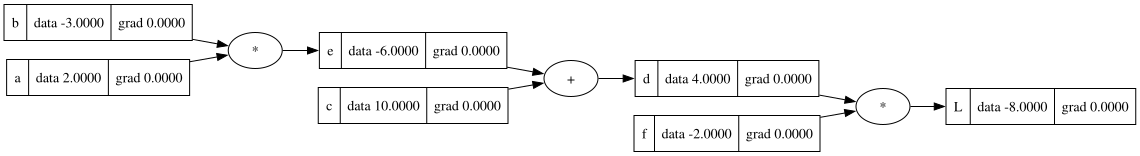

In [9]:

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root, format='svg', rankdir='LR'):
    """
    format: png | svg | ...
    rankdir: TB (top to bottom graph) | LR (left to right)
    """
    assert rankdir in ['LR', 'TB']
    nodes, edges = trace(root)
    dot = Digraph(format=format, graph_attr={'rankdir': rankdir}) #, node_attr={'rankdir': 'TB'})
    
    for n in nodes:
        dot.node(name=str(id(n)), label = "{%s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            dot.node(name=str(id(n)) + n._op, label=n._op)
            dot.edge(str(id(n)) + n._op, str(id(n)))
    
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    
    return dot
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
f = Value(-2.0, label='f')
e = a * b; e.label = 'e'
d = e + c; d.label = 'd'
h = 0.0001
L = d * f; L.label = 'L'
draw_dot(L)

In [10]:
# in the neural nets the derivatives we need in the propagation for comparing the final output
#with each intermediate nodes that causes to get the final answer

# in this way we need to update the weights of the neural nets. based on the d(loss function) w.r.t the each value.

### Change in the variable how it is impacting on the loss function(final output answer)
# data is fixed, in each iterations weigths are updated

# initially grad is zero, there is no impact of each in the final L.

In [11]:
#finding the derivative of L wrt a by adding a small value of h. for checking all gradients.
def derivative():
    h = 0.000001
    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    f = Value(-2.0, label='f')
    e = a * b; e.label = 'e'
    d = e + c; d.label = 'd'
    L = d * f; L.label = 'L'



    L1 =L.data

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    f = Value(-2.0, label='f')
    e = a * b; e.label = 'e'
    d = e + c ; d.label = 'd'
    c.data = c.data+h
    L = d * f; L.label = 'L'



    L2 =  L.data

    # print('L1', L1)
    # print('L2', L2)

    slope = (L2-L1)/h
    print(slope)

derivative()

0.0


1.000000000139778


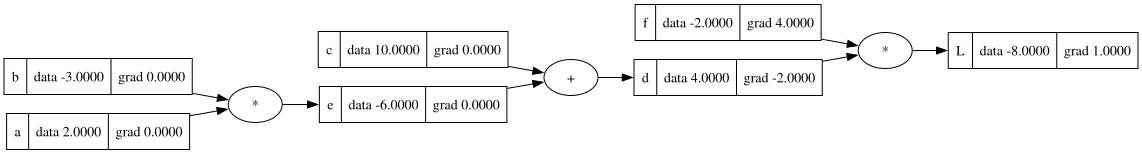

In [12]:
# base case

a = Value(2.0 , label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
f = Value(-2.0, label='f')
e = a * b; e.label = 'e'
d = e + c; d.label = 'd'
h = 0.000001
L = d * f; L.label = 'L'

L1 =  L.data
L2 = L.data +h
grad_of_L = (L2-L1)/h
print(grad_of_L)
# grad of L is  1.000000000139778 -- take it as one and update.
L.grad =1

#finding all derivates with.r.t to L.
# derivative of the L w.r.t to d, f
# L = d*f
# dl/dd =  ((d+h)f - df) /h
# df + hf - df / h = f
# finding the grad of L by changing h.
grad_of_d = f.data;
d.grad = grad_of_d

# exactly as above
grad_of_f = d.data;
f.grad = grad_of_f
draw_dot(L)


1.000000000139778


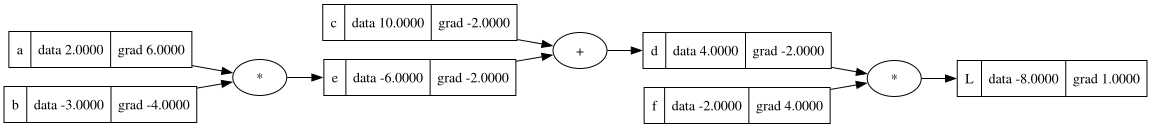

In [13]:
a = Value(2.0 , label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
f = Value(-2.0, label='f')
e = a * b; e.label = 'e'
d = e + c; d.label = 'd'
h = 0.000001
L = d * f; L.label = 'L'

L1 =  L.data
L2 = L.data +h
grad_of_L = (L2-L1)/h
print(grad_of_L)
# grad of L is  1.000000000139778 -- take it as one and update.
L.grad =1

grad_of_d = f.data;
d.grad = grad_of_d

grad_of_f = d.data;
f.grad = grad_of_f

# chain rule we are getting
c.grad = grad_of_d ; # other value is 1 is chain due to h/h
e.grad = grad_of_d;

# now again backwards to chain rule to e w.r.t a and b.
# de/da and de/db.
# we want dL/da = dL/de * de/da
# e = a*b
# f(x+h)-f(a) /h 
# getting de/da = b(-3.00), de/db = a(2.00)
# overall
#dl/da = 6.00, dl/db = -4.00
a.grad = 6.0
b.grad = -4.0
draw_dot(L)


In [14]:
xs = np.arange(-5,5, 0.2) 
ys = np.tanh(xs)
plt.plot(xs,ys)
plt.grid()

NameError: name 'np' is not defined

# why do we need the tanh or sigmoid functions?
- without the functions will increase linearly layer by layer it increases or decreases based on the given function but it must confirmly goes in the linear pattern.
- Their essential job is to introduce non-linearity so neural networks can learn complex patterns instead of being limited to linear relationships.


In [15]:
# inputs x1,  x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
#bias
b = Value(6.88813, label='b')

w1x1 = w1*x1 ; w1x1.label ='w1x1'
w2x2 = w2*x2 ; w2x2.label ='w2x2'

w1x1w2x2 = w1x1+w2x2 ; w1x1w2x2.label='w1x1w2x2'

n = w1x1w2x2 + b; n.label ='n'
o = n.tanh(); o.label='o'

o.grad =1
o._backward()


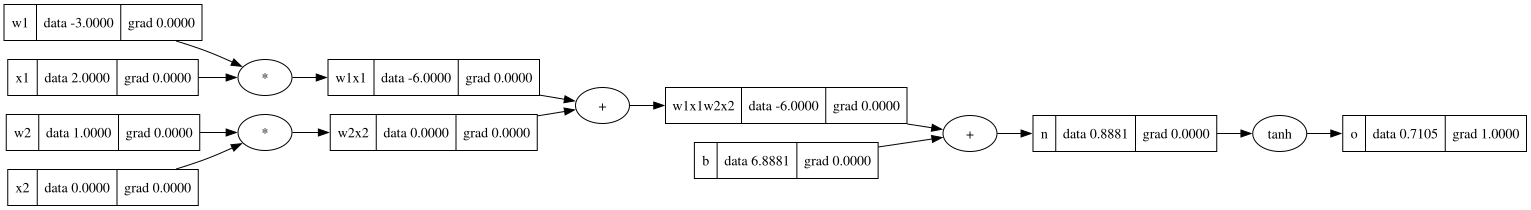

In [16]:
n._backward()

# w1x1w2x2._backward()

# w1x1._backward()
# w2x2._backward()
draw_dot(o)

In [17]:
o.data

0.7104688741009038

In [18]:
n_grad = 1-o.data**2
n_grad

0.49523397893379417

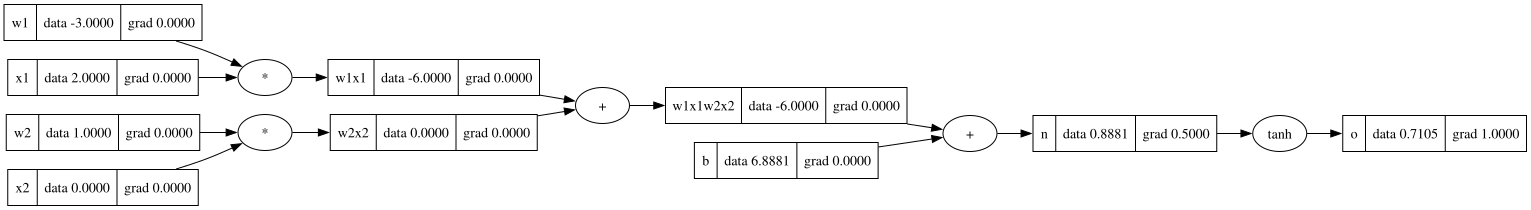

In [19]:
n.grad =0.5
o.grad =1
draw_dot(o)

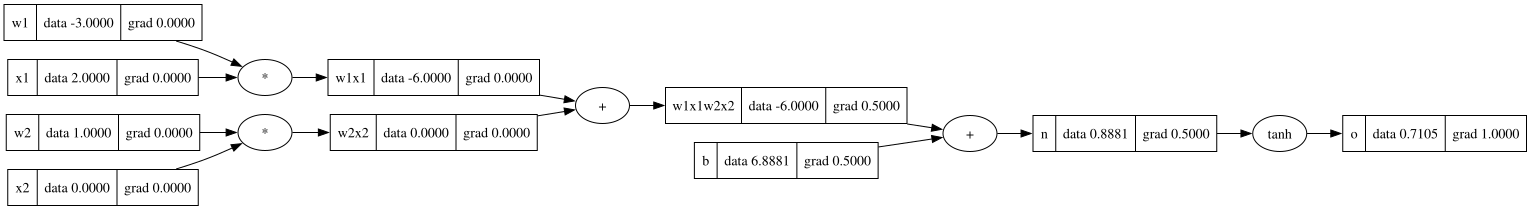

In [20]:
w1x1w2x2.grad =0.5
b.grad = 0.5
draw_dot(o)

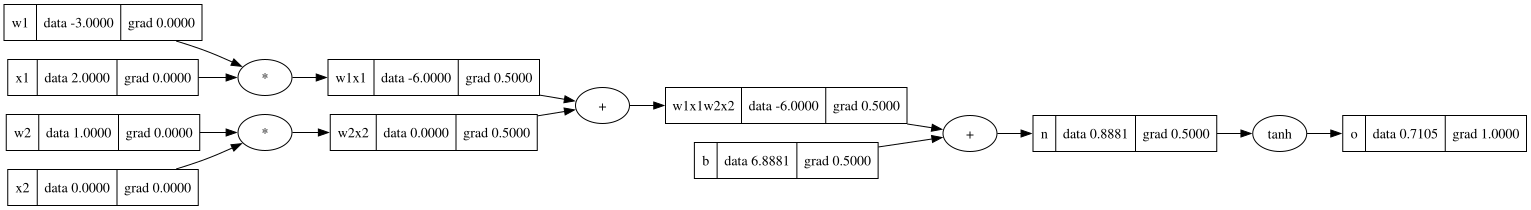

In [21]:
w1x1.grad=0.5
w2x2.grad=0.5
draw_dot(o)

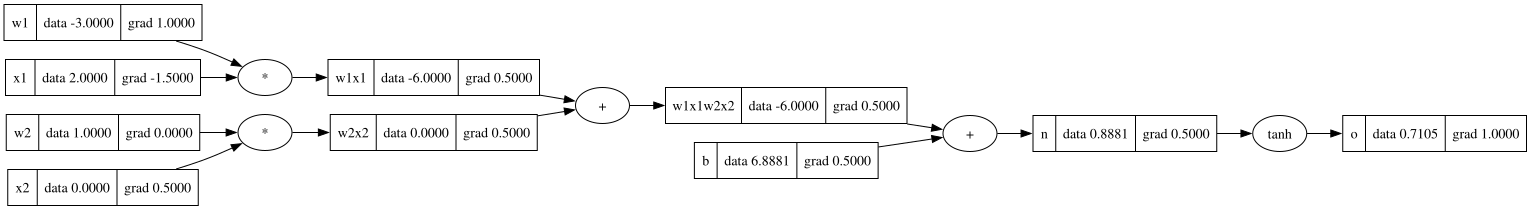

In [22]:
w2.grad = w2x2.grad * x2.data
x2.grad = w2x2.grad * w2.data


w1.grad = w1x1.grad * x1.data
x1.grad = w1x1.grad * w1.data
draw_dot(o)

In [23]:
# now we added the backward functions in the class , using it we don't need to calculate the grad manually just call the functions , 
#which fills the backwards
# o.grad =1
# draw_dot(o)
# o._backward()

# n._backward()

# w1x1w2x2._backward()

# w1x1._backward()
# w2x2._backward()
# draw_dot(o)
# a bug in it

In [24]:
# fill all the roots at a time using the backward function and topological sort by visiting all nodes at a time and implement it in the class


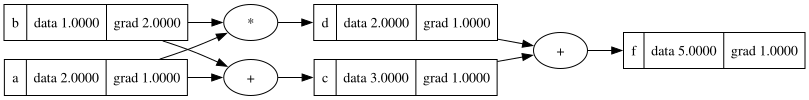

In [25]:
# a classical bug is hiding behind it, that gradients are overring in the backward function in few cases like.
a = Value(2.0, label='a')
b = Value(1.0, label='b')

c = a+b ; c.label='c'
d = a*b ; d.label='d'
f = c+d ; f.label='f'
f.grad=1
f._backward()
c._backward()
d._backward() # need fix it in the above class by adding not by overring =, use +=
draw_dot(f)

In [26]:
a = Value(2.0)
a+1

value(data=3.0)

In [27]:
import torch
x1 = torch.Tensor([2.0]).double() ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double() ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double() ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double() ; w2.requires_grad = True

b = torch.Tensor([6.88813]).double() ; b.required_grad = True

n = x1*w1 + x2*w2 + b 
o = torch.tanh(n)

print(o.data.item())
o.backward()

print("-----")
print('x1', x1.grad.item())
print('x2', x2.grad.item())
print('w1', w1.grad.item())
print('w2', w2.grad.item())


0.7104689671990757
-----
x1 -1.485701539941236
x2 0.4952338466470787
w1 0.9904676932941574
w2 0.0


In [28]:
torch.tensor([[1, 2, 3], [4, 5, 6]])
torch.Tensor([[1, 2, 3], [4, 5, 6]]).shape

torch.Size([2, 3])

In [29]:
print(o)
print(o.item())



tensor([0.7105], dtype=torch.float64, grad_fn=<TanhBackward0>)
0.7104689671990757


pytorch is more efficient it has already much implemented micrograd

[(value(data=0.5970042257738104), 2.0), (value(data=-0.6444892023775626), 3.0), (value(data=0.25385389249444046), -1.0)]
[(value(data=0.42281268058111987), 2.0), (value(data=-0.07151947203513043), 3.0), (value(data=0.583176230847815), -1.0)]
[(value(data=0.5872283757515118), 2.0), (value(data=-0.1809676672211833), 3.0), (value(data=-0.6644589762462563), -1.0)]
[(value(data=-0.20203111351170966), 2.0), (value(data=-0.9814147723562932), 3.0), (value(data=-0.681764308297159), -1.0)]
[(value(data=0.17191778355092402), value(data=-0.8806129945220158)), (value(data=-0.5096592452834106), value(data=0.6676196408573336)), (value(data=-0.7526170062290505), value(data=0.6286528093186458)), (value(data=-0.46233691023159085), value(data=-0.9911346538228065))]
[(value(data=0.5143771235406114), value(data=-0.8806129945220158)), (value(data=-0.2534867732329926), value(data=0.6676196408573336)), (value(data=0.8197671568415941), value(data=0.6286528093186458)), (value(data=0.3459785573841023), value(dat

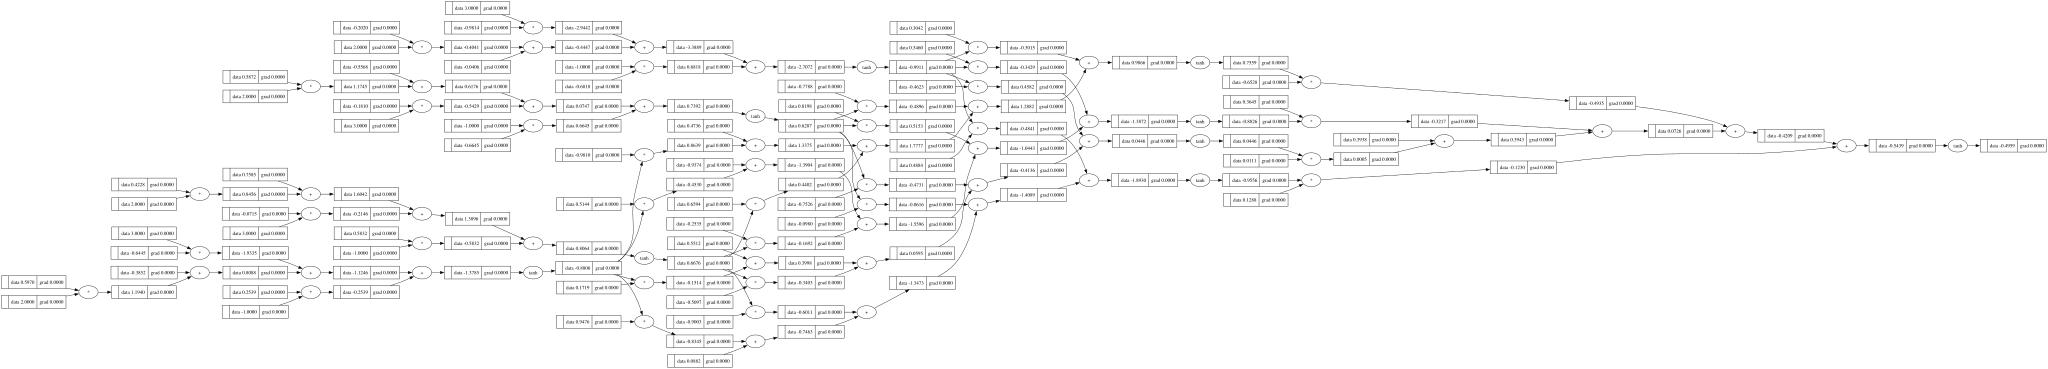

In [38]:
import random

class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))

    def __call__(self, x):
        print(list(zip(self.w, x)))
        act = sum((wi*xi for wi,xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

#layers with no of neurons.
class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs)==1 else outs 

class MLP:
    def __init__(self, nin, nouts):
        sz = [nin]+ nouts
        self.layers = [Layer(sz[i],sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x
        

x = [2.0, 3.0, -1.0] #inputs
# n = Neuron(2)
# n = Layer(2, 3)
mlp = MLP(3, [4, 4, 1]) # each layer outputs
mlp(x)
draw_dot(mlp(x))

In [36]:
xs =[
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]
ys=[1.0, -1.0, -1.0, 1.0] #desired outputs
ypred = [mlp(x) for x in xs]
ypred         

[(value(data=0.9429110115245289), 2.0), (value(data=-0.8494126567058933), 3.0), (value(data=-0.4633934584206387), -1.0)]
[(value(data=-0.7576500568267928), 2.0), (value(data=0.7002412650786833), 3.0), (value(data=-0.927004161149297), -1.0)]
[(value(data=0.48972126040286), 2.0), (value(data=-0.9987558894122242), 3.0), (value(data=0.6481954210540892), -1.0)]
[(value(data=0.1650758916558357), 2.0), (value(data=-0.5864357681838983), 3.0), (value(data=-0.8431195001786558), -1.0)]
[(value(data=-0.7359209173584409), value(data=-0.1988827084874173)), (value(data=0.4925831921761217), value(data=0.7830110184884401)), (value(data=0.5996568620084044), value(data=-0.9873432241569925)), (value(data=0.3631198867623784), value(data=-0.9031210252794121))]
[(value(data=-0.5814053601676197), value(data=-0.1988827084874173)), (value(data=0.493051803134845), value(data=0.7830110184884401)), (value(data=0.9085295304436978), value(data=-0.9873432241569925)), (value(data=-0.7639005612438281), value(data=-0.90

[value(data=0.4042915080447647),
 value(data=0.04827439294200994),
 value(data=0.02776796961839341),
 value(data=0.39812183808544177)]

In [42]:
[(yout-ypred)**2 for ypred,yout in zip(ys, ypred)]

TypeError: unsupported operand type(s) for -: 'Value' and 'float'